In [ ]:
from pathlib import Path
import runpy
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score,
)

ROOT = Path(r"C:\projects\projectAI\GangNaengI_AI")
script = ROOT / "src" / "evalution.py"
if not script.is_file():
    script = ROOT / "src" / "evaluation.py"
if not script.is_file():
    raise FileNotFoundError(f"평가 Python 파일을 찾지 못했습니다: {ROOT / 'src'}")

context = runpy.run_path(str(script))

RESULTS = context["RESULTS"]
MODELS = context["MODELS"]
PROCESSED = context["PROCESSED"]
X_test = context["X_test"]
y_test = context["y_test"]
X_train = context["X_train"]
models = context["models"]
results_df = context["results_df"]
xgb_model = context["xgb_model"]

print("평가 실행 파일:", script)
print("모델:", list(models))
print("평가 결과:", results_df.shape)


Test X:  (543, 10)
Test y:  (543,)
ML 모델 로딩 완료
MLP 모델 로딩 완료
Logistic Regreesion 예측 확률 개수:  543
XGBoost 예측 확률 개수:  543
PyTorch MLP 예측 확률 개수:  543

=== FINAL TEST RESULTS===
              model  threshold  accuracy  precision   recall       f1  roc_auc  average_precision
        PyTorch MLP        0.3  0.583794   0.442177 0.677083 0.534979 0.655723            0.53603
Logistic Regreesion        0.5  0.683241   0.666667 0.208333 0.317460 0.662823            0.53659
            XGBoost        0.5  0.661142   0.576923 0.156250 0.245902 0.632620            0.50212
불러온 평가 코드: C:\projects\projectAI\GangNaengI_AI\src\evalution.py
필요한 변수와 라이브러리 연결 확인 완료


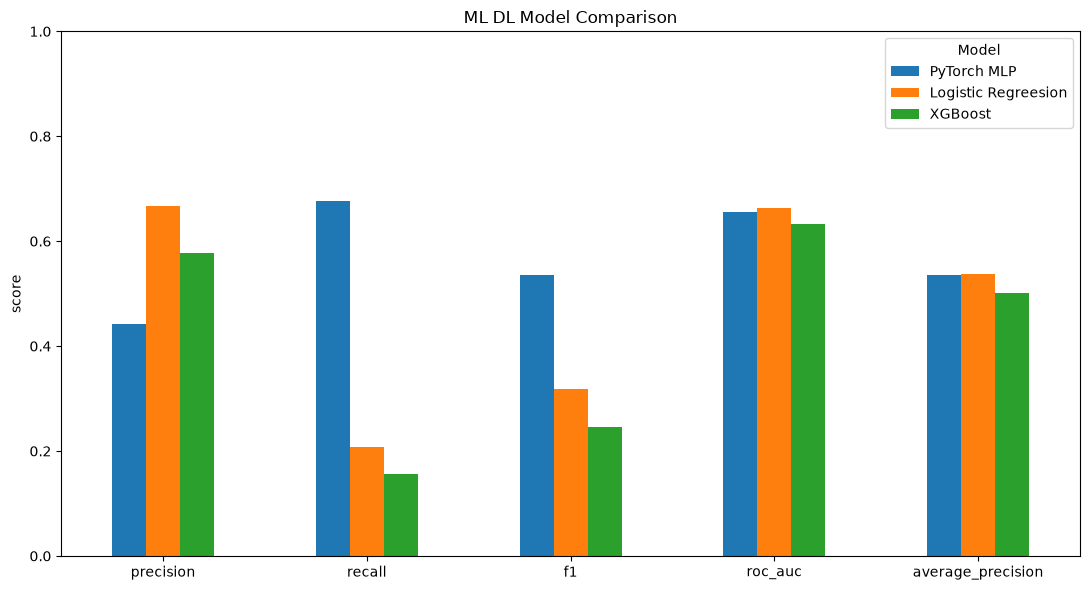

In [ ]:
# 7. ML DL 성능 비교 그래프 --------------------------------------------------------------------------------------

# 그래프 표기할 것들
metrics = [
  "precision", # 재현율
  "recall",    # 재현율
  "f1",        # F1 스코어
  "roc_auc",   # ROC 곡선 아래 면적 계산
  "average_precision" # 평균 정밀도
]

plot_df = results_df.set_index("model")[metrics] # .set_index() = 특정 열을 행 인덱스로 지정
                                                 # [metrics] = metrics 리스트에 포함된 열만 추출

ax = plot_df.T.plot( # .T = Transpose(전치)
                     #      행과 열을 서로 교환
                     # .plot() = DF 그래프 시각화
  kind="bar", # kind = 그래프 종류 설정
              # bar  = 믹대그래프 
  figsize=(11, 6), # figsize = 그래프 사이즈
                   # --> 그래프 가로 11인치 + 세로 6인치
  rot=0 # rot = Rotation
)       #       X축 눈금 라벨 회전 각도
        #       딱히 성능은 아니고 이름이 어떻게 나오느냐임(디자인적 영역)
        #       이름        름
        #                 이
        #       이런 정도?
        # rot=0 = 눈금 라벨 회전 x

ax.set_title("ML DL Model Comparison") # ax = Axes 객체 저장할 변수
                                       # Axes = Matplotlib의 그래프의 영역 관리
                                       #        한마디로 디자인적인 영역
                                       # set_title() = 그래프 제목
ax.set_ylabel("score") # set_ylabel() = y 라벨 설정
ax.set_ylim(0, 1) # set_ylim() = y축의 표시 범위 설정
                  #              lim = limit
ax.legend(title="Model") # .legand() = 그래프 범례 표시 및 설정
                         # title = 범례 제목 설정
                         # 범례: 그래프의 색상 및 기호가 무엇인지 알려줌
                         #       ex) 초록색 막대그래프 = 식물의 키
                         #           갈색 막대그래프   = 나무의 키
plt.tight_layout() # plt = 그래프
                   # tight_layout() = 여백 자동 조절
plt.savefig( # savefig() = 현 figure를 이미지로 저장
  RESULTS / "model_comparision.png", # 성능 비교 그래프 사진 =
                                     # C:\projects\projectAI\GangNaengI_AI\results\model_comparision.png
  dpi=150 # dpi = 이미지 해상도                              
)         # 1인치당 150개의 점으로 구성된 해상도

plt.show() # 그래프 출력       


In [ ]:
# 8. Confusion Matrix 생성 --------------------------------------------------------------------------------------

# Confusion Matrix = 혼동행렬
# 혼동행렬 - TP TN FP FN의 데이터 개수 확인
#   T = True(참)        P = Positive(양성)
#   F = False(거짓)     F = negative(음성)
#   TN[진음성] = 예측성공 | 실제라벨=0 예측라벨=0 | 음성을 음성으로 예측
#   TP[진양성] = 예측성공 | 실제라벨=1 예측라벨=1 | 양성을 양성으로 예측
#   FN[위음성] = 예측실패 | 실제라벨=1 예측라벨=0 | 양성을 음성으로 예측
#   FP[위양성] = 예측실패 | 실제라벨=0 에측라벨=1 | 음성을 양성으로 예측 

for name, info in models.items(): # name     = 모델명
                                  # info     = 모델 정보
                                  # .items() = dict의 Key와 Value 반환
  y_pred = ( # y_pred = 예측라벨
    info["prob"] >= info["threshold"] # prob = 모델 예측확률 배열
                                      # threshold = 모델 분류 임계값
  ).astype(int) # .astype() = 배열을 자료형으로 변환

  # 혼동행렬 생성 - 실제 라벨과 예측라벨 비교
  cm = confusion_matrix(
    y_test, # 테스트데이터의 정답라벨
    y_pred, # 모델의 예측라벨
    labels=[0, 1] # labels = 라벨 배치 순서
  )               # [0, 1] = 음성에서 양성 순으로 배치
                  # [1, 0] = 양성에서 음성 순으로 배치

  # 혼동행렬 시각화
  disp = ConfusionMatrixDisplay( # ConfusionMatrixDisplay = 혼동행렬 시각화
    confusion_matrix=cm, # confusion_matrix = 시각화할 혼동행렬 전달
    display_labels=["Negative", "Positive"] # display_labels = 그래프의 라벨명 지정
  )                                         # 라벨명: Negative = 음성 | Positive = 양성

  disp.plot( # .plot() = 그래프 그려라
    cmap="Blues", # cmap = Color Map
                  # Color Map = 데이터 수치에 따라 색상 정함
                  #             ex) 진한파랑, 중간파랑, 연한파랑 ... 
    values_format="d" # values_format = 혼동행렬 내부 숫자 출력 형식 지정
  )                   # d = 십진정수 형식

  plt.title(f"{name} - Confusion Matrix") # .title() = 그래프 제목
  plt.tight_layout() # tight_layout() = 그래프 여백 자동 조절

  # 이미지 파일명 지정
  filename = (
    name.lower() # .lower() = 소문자
                 # .upper() = 대문자
    .replace(" ", "_") # .replace() = 문자열 바꿔라
                       # 해석: 빈칸을 _로 바꿔라
    + "_confusion_matrix.png" # 해석: 맨 끝은 _confusion_matrix.png 이걸로 지정하라
  )                           # ex) logistic_regression_confusion_matrix.png
                              #     xgboost_confusion_matrix.png
                              #     pytorch_mlp_confusion_matrix.png

  plt.savefig( # .savefig() = 현 Figure를 이미지로 바꿔 저장
    RESULTS / filename, # 이미지 위치 = C:\projects\projectAI\GangNaengI_AI\results\파일이미지명
    dpi=150 # dpi = 해상도
  )         # 해석: 1인치당 점 150개의 해상도

  plt.show() # 그래프 출력

  # 혼동행렬 TN FP FN TP 추출
  tn, fp, fn, tp = cm.ravel() # .ravel() = 다차원 NP를 일차원 NP로 바꿔라

  print(f"\n{name}")
  print(f"TP: {tp}, TN: {tn}")
  print(f"FP: {fp}, FN: {fn}")

In [ ]:
# 9. ROC Curve --------------------------------------------------------------------------------------------------

# ROC 곡선 = ROC Curve
#   roc_curve = 여러 임계값의 FPR과 TPR 계산
#   FPR[위양성률] = 실제 음성인 환자를 양성으로 판단한 경우
#                   식: FPR = FP + TN / FP
#   TPR[진양성률] = 실제 양성인 환자를 양성으로 판단한 경우
#                   식: TPR = TP + FN / TP

plt.figure(figsize=(9, 6)) # .figure() = Figure 객체 생성
                           # figsize   = Figure 사이즈 지정
                           #             가로 9인치 + 세로 6인치

for name, info in models.items(): # name = 모델명
                                  # info = 모델 예측확률 및 임계값 정보
                                  # .items() = dict의 key와 value 반환
  fpr, tpr, thresholds = roc_curve( # fpr = 위양성률
                                    #       실제 음성을 양성으로 판단
                                    # tpr = 진양성률
                                    #       실제 양성을 양성으로 판단
                                    # thresholds  = FPR TPR 계산시 사용하는 임계값 배열
                                    # roc_curve() = 여러 임계값에 따른 FPR과 TPR 계산
    y_test, # 실제 정답라벨
    info["prob"] # info = 모델 정보
  )              # prob = 확률

  # ROC-AUC 계산
  auc = roc_auc_score( # roc_auc_score() = ROC 곡선 아래 면적 계산
    y_test, # 실제 정답라벨
    info["prob"] # info = 모델 정보
  )              # prob = 확률

  # 모델별 ROC 곡선 그리기
  plt.plot( # .plot() = 그래프 
    fpr, # FPR = X축 데이터
    tpr, # TPR = y축 데이터
    label=f"{name} (AUC={auc:.3f})" # label = 범례명 지정
  )                                 # name  = 모델명 
                                    # {AUC:.3f} = AUC 점수를 소수점 3자리까지
                                    # : = 출력형식지정 | .3 = 소수점 3자리 | f = 고정소수점

# 무작위 분류 기준선
plt.plot( # .plot() = 그래프 
  [0, 1], # [0, 1] = X축 좌표
  [0, 1], # [0, 1] = y축 좌표
          # 해석: 시작좌표가 0 종료좌표가 1
  "k--",  # k-- = 검은색 점선으로 표기
          # r- = 빨간실선 | b: = 파란점선 | g-. = 초록일점쇄선
  label="Random Baseline" # label = 범례명 지정
)  

plt.xlabel("False Positive Rate") # .xlabel() = X축라벨 설정
plt.ylabel("True Positive Rate")  # .ylabel() = y축라벨 설정
plt.title("ROC Curve - ML vs DL") # .title()  = 제목 설정
plt.legend() # .legend() = 범례 표기
plt.tight_layout() # tight_layout() = 여백 자동 조절

# ROC 곡선 이미지 저장
plt.savefig( # .savefig() = Figure를 이미지로 저장
  RESULTS / "roc_curve.png", # 이미지 위치: C:\projects\projectAI\GangNaengI_AI\results\roc_curve.png
  dpi=150 # dpi = 해상도
)         # 해석: 1인치당 150 픽셀(= 점이 150개)

plt.show() # 그래프 출력

In [ ]:
# 10. PR Curve --------------------------------------------------------------------------------------------------

# PR Curve = 정밀도와 재현율 관계를 보여줌
#            양성과 음성을 얼마나 잘 구분하는지 알 수 있음

plt.figure(figsize=(9, 6)) # .figure() = Figure를 생성하라
                           # figsize = Figure 사이즈 --> 가로 9인치 + 세로 6인치

#
for name, info in models.items(): # name = 모델명
                                  # info = 모델 정보
                                  # .items() = dict의 key와 value 반환
  precision, recall, thresholds = ( # precision = 정밀도
                                    # recall = 재현율
                                    # thresholds = 임계값 배열
    # PR 곡선                                
    precision_recall_curve( # precision_recall_curve() = 정밀도와 재현율의 곡선(PR 곡선)
      y_test, # 테스트의 정답라벨
      info["prob"] # info = 모델 정보
    )              # prob = 확률
  )

  # AP - 평균정밀도
  ap = average_precision_score(
    y_test, # 테스트의 정답라벨
    info["prob"] # info = 모델 정보
  )              # prob = 확률            
  
  plt.plot( # .plot = 그래프
    recall,    # 재현율
    precision, # 정밀도
    label=f"{name} (AP={ap:.3f})" # label = 범례명 지정
  )                               # name  = 모델명
                                  # AP = 평균 정밀도 곡선
                                  # {ap:.3f} = ap를 소수점 3자리까지
                                  # : = 형식지정 | .3 = 소수점3자리 | f = 고정소수점
  
  # 테스트 데이터의 양성비율
  baseline = np.mean(y_test) # .mean() = 중앙값
  
  plt.axhline( # .axhline() = y축에 수평선 그려라
    baseline,  # 테스트데이터의 양성비율
    color="gray", # 색상은 회색
    linestyle="--", # 선은 점선으로
    label=f"Positive Rage={baseline:.3f}" # label = 범례명 지정
  )                                       # :.3f = 소수점 3자리
                                          # : = 형식지정 | .3 = 소수점3자리 | f = 고정소수점

  plt.xlabel("Recall") # .xlabel()    = X축라벨 설정
  plt.ylabel("Precision") # .ylabel() = y축라벨 설정
  plt.title("Precision-Recall Curve") # .title() = 그래프 제목
  plt.legend() # .legand() = 범례 표기
  plt.tight_layout() # tight_layout() = 여백 자동 설정   

  # PR Curve 이미지 저장
  plt.savefig( # .savefig() = Figure를 이미지로 저장
    RESULTS / "pr_curve.png", # PR Curve 이미지 위치 = C:\projects\projectAI\GangNaengI_AI\results\pr_curve.png
    dpi=150 # dpi = 해상도
  )         # 해석: 1인치당 점 150개 == 픽셀이 150개

  plt.show() # .show() = 그래프 출력

In [ ]:
# 11. 전처리 입력 변수명 복원 ----------------------------------------------------------------------------------------

# SHAP = 모델 예측 결과에 대한 각 입력특성의 기여도 분석
#        요약: 어떤 입력특성이 예측값을 얼마나 높이고 낮췄는가

# SHAP 분석 클래스 - 분석 대상
# TreeExplainer   - 트리기반 모델 ex) XGBoost, RandomForest
# LinearExplainer - 로지스틱 회귀 모델
# DeepExplainer   - 딥러닝 신경망
# KerneExplainer  - 다양한 모델 아무거나

# 입력 변수 = 연령, 나이, 성별, 흡연 

# 전처리 변수 이름 복원
preprocessor = joblib.load( # joblib  = 파이썬 객체를 저장 및 불러오기
                            # .load() = 파일의 객체 불러와라
  MODELS / "preprocessor.joblib" # 전처리 파일 위치 = C:\projects\projectAI\GangNaengI_AI\models\preprocessor.joblib
)

# 전처리 입력 특성 이름 복원
feature_names = preprocessor.get_feature_names_out() # feature_names = 전처리된 입력특성명
                                                     # preprocessor  = 전처리 객체
                                                     # get_feature_names_out() = feature_names의 배열로 반환
print("전처리된 특성 개수: ", len(feature_names)) # len() = 길이
print("특성 이름: ", feature_names) # feature_names = 전처리된 입력특성명

assert len(feature_names) == X_test.shape[1] # assert = 조건이 True면 실행
                                             #          아니면 False라서 AssertionError 발생
                                             # .shape = 행과 열을 튜플로 반환 
                                             # .shape[1] = 튜플 인덱스 1번 값인 열의 개수
                                             # 해석: 입력변수의 개수 == 테스트데이터의 입력데이터의 1번 열의 개수

In [ ]:
# 12. XGBoost SHAP 중요도 계산 -----------------------------------------------------------------------------------

# 테스트데이터 일부 사용 
# --> 속도를 위해
X_sample = X_test[:200] # [:200] = 인덱스 0~199까지 추출하라

# TreeExplainer 생성
explainer = shap.TreeExplainer(xgb_model) # explainer = 모델예측 결과 설명용 객체
                                          # shap = 모델예측 결과의 입력 특성 기여도 분석
                                          # .TreeExplainer() = 트리모델의 SHAP 분석
                                          # SHAP = 모델 예측 결과에 대한 각 입력특성의 기여도 분석
                                          # xgb_model = XGBoost 모델
                                          
                                          # SHAP 분석 클래스 - 분석 대상
                                          # TreeExplainer   - 트리기반 모델 ex) XGBoost, RandomForest
                                          # LinearExplainer - 로지스틱 회귀 모델
                                          # DeepExplainer   - 딥러닝 신경망
                                          # KerneExplainer  - 다양한 모델 아무거나
# SHAP 값 계산
shap_values = explainer(X_sample) # shap_values = SHAP 분석 결과
                                  # X_sample = SHAP 분석용 데이터 200건

# 특성별 평균 절대값(SHAP) 기여도
importance = np.abs( # importance = 입력 특성별 중요도
                     # .abs() = NP로 숫자 절대값 반환
                     # 절대값: 0과의 거리
  shap_values.values # shap_values = SHAP 분석 결과
                     # .values = 계산된 SHAP 수치 배열로 반환
).mean(axis=0) # .mean() = 평균값
               # axis = 배열 축 지정
               # axis=0 = 행 방향
               # axis=1 = 열 방향

shap_df = pd.DataFrame({ 
  "feature": feature_names, # feature = 입력 특성명의 컬럼명
                            # feature_names = 전처리 입력 특성명 배열
  "mean_abs_shap": importance # mean_abs_shap = 평균 절대 SHAP값
})                            # important = 계산한 특성별 중요도 배열

# 중요도 내림차순
shap_df = shap_df.sort_values( # .sort_values() = 지정한 컬럼의 값을 정렬
  by="mean_abs_shap", # by = 정렬 기준 컬럼명을 지정
                      # mean_abs_shap = 평균 절대 SHAP값
  ascending=False # ascending = 정렬 기준
)                 # True = 오름차순 | False = 내림차순

print("\n=== SHAP Feature Important ===")
print(shap_df)

# SHAP 중요도 시각화
plt.figure(figsize=(10, 6)) # .figure() = Figure 생성
                            # figsize   = Figure 사이즈 --> 가로 10인치 + 세로 6인치 

plt.barh( # .barh() = 가로 막대그래프 생성
  shap_df["feature"][::-1], # feature = 입력 특성명 컬럼을 추출
                            # [::-1]  = 데이터 순서를 역순으로 변경
  shap_df["mean_abs_shap"][::-1] # mean_abs_shap = 평균 절대 SHAP값
)                                # [::-1]  = 데이터 순서를 역순으로 변경

plt.xlabel("Mean Absolute SHAP Value") # .xlabel() = X축라벨 지정
plt.title("XGBosot - SHAP Feature Important") # .title() = 제목
plt.tight_layout() # .tight_layout() = 여백 자동 조절

# SHAP 이미지 저장
plt.savefig( # .savefig() = Figure를 이미지로 저장
  RESULTS / "shap_important.png", # SHAP 이미지 위치 = C:\projects\projectAI\GangNaengI_AI\results\shap_important.png
  dpi=150 # dpi = 해상도
)         # 해석: 1인치당 점(픽셀)이 150개

plt.show() # .show() = 그래프 출력

In [ ]:
# 13. 오분류 사례 분석 -------------------------------------------------------------------------------------------

# 목적:
# 어떤 모델이 FN을 가장 많이 발생시켰는가?
# FP가 얼마나 발생했는가?
# 모델이 높은 확률로 예측했는데도 틀린 사례가 있는가?
# ML과 DL의 오류 패턴이 서로 다른가?

# 오분류 결과
error_results = []

# 모델별 예측 라벨 생성
for name, info in models.items(): # name = 모델명
                                  # info = 모델 정보
                                  # .items() = dict에 key와 value 반환
  predictions = ( # predictions = 모델 예측라벨 배열
    info["prob"] >= info["threshold"] # 모델 예측 확률 >= 모델 분류 임계값
  ).astype(int) # .astype() = 배열을 자료형으로 변경

  # 오분류 데이터 탐색
  for i in range(len(y_test)): # y_test = 테스트데이터 정답라
    if predictions[i] != y_test[i]: # predictions[i] = 인덱스 i인 예측라벨 
                                    # y_test[i] = 인덱스 i인 정답라벨
      # 오분류 유형 결정                              
      error_type = ( # error_type = 오분류 타입
        "FN" if y_test[i] == 1 else "FP" # Ture면 FN(위음성)
      )                                  # False면 FP(위양성)
      # TN[진음성] = 예측성공 | 실제라벨=0 예측라벨=0 | 음성을 음성으로 예측
      # TP[진양성] = 예측성공 | 실제라벨=1 예측라벨=1 | 양성을 양성으로 예측
      # FN[위음성] = 예측실패 | 실제라벨=1 예측라벨=0 | 음성을 양성으로 예측
      # FP[위양성] = 예측실패 | 실제라벨=0 에측라벨=1 | 양성을 음성으로 예측

      # 오분류표 상세 정보 저장
      error_results.append({ # .append() = 리스트에 추가
        "model": name, # 모델명
        "test_row": i, # 테스트데이터 행 인덱스
        "actual": int(y_test[i]), # 실제 정답라벨
        "predicted": int(predictions[i]), # 모델 예측라벨
        "probability": float(info["prob"][i]), # 모델 양성 예측 확률
        "error_type": error_type # 오분류 유형
      })

error_df = pd.DataFrame(error_results) # error_results = 오분류 결과

print("\n=== Error Type Counts ===")
print(
  error_df.groupby( # .groupby() = 컬럼을 동일한 값을 기준으로 데이터 그룹화
    ["model", "error_type"] # model = 모델
                            # error_type = 오분류 타입
  ).size() # .size() = 각 그룹에 포함된 행의 개수 반환
)

# 오분류 결과 저장
error_df.to_csv( # .to_csv() = CSV로 저장  
  RESULTS / "error_analysis.csv", # 오분류 결과 파일 = C:\projects\projectAI\GangNaengI_AI\results\error_analysis.csv
  index=False # index = 인덱스 행 같이 저장 유무
)             # True = 저장 | False = 저장 x

print("\n === False Negative Examples ===")
print(
  error_df[
    error_df["error_type"] == "FN" # error_type = 오분류 타입
                                   # 해석: error_type이 FN인 것만 출력
    # 오분류 타입                               
    # TN[진음성] = 예측성공 | 실제라벨=0 예측라벨=0 | 음성을 음성으로 예측
    # TP[진양성] = 예측성공 | 실제라벨=1 예측라벨=1 | 양성을 양성으로 예측
    # FN[위음성] = 예측실패 | 실제라벨=1 예측라벨=0 | 음성을 양성으로 예측
    # FP[위양성] = 예측실패 | 실제라벨=0 에측라벨=1 | 양성을 음성으로 예측                                   
  ].head(10) # .head(10) = 앞의 10개만 출력
)

In [ ]:
# 14. 결과 요약 --------------------------------------------------------------------------------------------------

print("\n" + "=" * 50)
print("GangNaengI AI - DAY 05 Evalution")
print("=" * 50)

print("\n[최종 모델 성능]")
print(results_df.to_string(index=False)) # .to_string() = DF를 str로
                                         # index = 인덱스 행 같이 출력 유무
                                         # True = 출력 | False = 출력 x

print("\n[SHAP 중요 특성 TOP 5]")
print(shap_df.head(5).to_string(index=False)) # .head(5) = 앞의 5개만 출력
                                              # .to_string() = DF를 str로
                                              # index = 인덱스 행 같이 출력 유무
                                              # True = 출력 | False = 출력 x

print("\n[오분류 개수]")
print(
  error_df.groupby( # .groupby() = 컬럼을 동일한 값을 기준으로 데이터 그룹화
    ["model", "error_type"] # model = 모델
                            # error_type = 오분류 타입
  ).size() # .size() = 각 그룹에 포함된 행의 개수 반환
)

print("day 05 - 모델 평가 및 분석 완료")